# Training Model Bi-LSTM Dataset Pidana 200

## Import Requirement

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch Version:', torch.__version__)
print('Device:', device)


PyTorch Version: 2.14.0+cu130
Device: cuda


## Set Parameter Training Model

In [3]:
BATCH_SIZE = 64  # Number of examples used in each iteration
EPOCHS = 100  # Number of passes through entire dataset
MAX_LEN = 10  # Max length of review (in words)
EMBEDDING = 100  # Dimension of word embedding vector

## Import Dataset Pidana 200

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')

data = pd.read_csv('LEGALNER-POS-PREV-NEXT-200.csv', encoding='latin1')
data['word'] = data['word'].astype(str).replace(to_replace=r'\d+', value=r'<\g<0>>', regex=True).replace(to_replace=r'[0-9]', value='X', regex=True)
data = data.ffill()


In [5]:
data

,doc,sentence,word,pos,prev,next,tag
0,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,PUTUSAN,PROPN,.,.,O
1,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,.,PUNCT,PUTUSAN,NOMOR,O
2,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,NOMOR,PROPN,.,:,O
3,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,:,PUNCT,NOMOR,1974,O
4,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,<XXXX>,NUM,:,/,B_VERN
...,...,...,...,...,...,...,...
1048570,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,Bahwa,SCONJ,-,mekanisme,O
1048571,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,mekanisme,NOUN,Bahwa,perpanjangan,O
1048572,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,perpanjangan,NOUN,mekanisme,dan,O
1048573,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,dan,CCONJ,perpanjangan,penambahan,O


In [6]:
data.groupby('tag').count()

,doc,sentence,word,pos,prev,next
tag,,,,,,
B_ADVO,322,322,322,322,322,322
B_ARTV,1912,1912,1912,1912,1912,1912
B_CRIA,102,102,102,102,102,102
B_DEFN,13034,13034,13034,13034,13034,13034
B_JUDG,315,315,315,315,315,315
B_JUDP,127,127,127,127,127,127
B_PENA,106,106,106,106,106,106
B_PROS,116,116,116,116,116,116
B_PUNI,178,178,178,178,178,178


In [7]:
data = data[data['pos'] != 'PUNCT']
data = data[data['pos'] != 'PRON']
data = data[data['pos'] != 'CCONJ']
data = data[data['pos'] != 'ADP']
data = data[data['pos'] != 'AUX']
data = data[data['pos'] != 'DET']
data = data[data['pos'] != 'ADV> Menimbang <VERB']
data = data[data['pos'] != ' <SYM']
data = data[data['pos'] != 'PROPN> LEL <PROPN']
data = data[data['pos'] != 'PROPN> _ <PROPN> Er <PROPN']
data = data[data['pos'] != 'PROPN> _ <PUNCT> IV <NUM']
data = data[data['pos'] != 'PROPN> _ <PROPN> Ep <PROPN']

In [8]:
# data[data['pos'] == 'PRON']

In [9]:
# data['pos'].unique()

In [10]:
# data['tag'] = data['tag'].apply(lambda x: [x])
# # Gabungkan tags dalam sentence yang sama dan hapus sentence yang hanya berisi tag 'O'
# df_combined = (
#     data.groupby(['doc', 'sentence'])['tag']
#     .agg(lambda x: sum(x, []))
#     .apply(lambda tags: tags if any(tag != 'O' for tag in tags) else [])
#     .reset_index(name='tag')
# )

# # Hapus baris yang tidak memiliki tag atau memiliki tag kosong
# df_combined = df_combined[df_combined['tag'].apply(lambda x: bool(x))]

# # Buat DataFrame baru hanya berisi baris yang sesuai dengan df_combined
# filtered_df = data[data['sentence'].isin(df_combined['sentence'])]

# # Pisahkan df_combined per tag dan isi sentence berdasarkan tag yang dipisah tadi
# result_rows = []
# for index, row in filtered_df.iterrows():
#     for tag in row['tag']:
#         result_rows.append({
#             'doc': row['doc'],
#             'sentence': row['sentence'],
#             'word': row['word'],
# #             'pos': row['pos'],
#             'prev': row['prev'],
#             'next': row['next'],
#             'tag': tag
#         })

# # Tampilkan dataframe setelah penggabungan, penghapusan, pemisahan kembali tags, dan pengisian kolom 'sentence'
# data = pd.DataFrame(result_rows)

# # Tampilkan dataframe hasil
# data

In [11]:
data.groupby('tag').count()

,doc,sentence,word,pos,prev,next
tag,,,,,,
B_ADVO,300,300,300,300,300,300
B_ARTV,1859,1859,1859,1859,1859,1859
B_CRIA,87,87,87,87,87,87
B_DEFN,10608,10608,10608,10608,10608,10608
B_JUDG,243,243,243,243,243,243
B_JUDP,83,83,83,83,83,83
B_PENA,106,106,106,106,106,106
B_PROS,101,101,101,101,101,101
B_PUNI,177,177,177,177,177,177


## Menambahkan token untuk Padding data

In [12]:
words = list(set(data["word"].values))
words.append("ENDPAD")
n_words = len(words)
n_words

17863

In [13]:
tags = list(set(data["tag"].values))
n_tags = len(tags)
n_tags

25

## Mengambil Data berdasarkan Dokumen dan Sentence

In [14]:
class SentenceGetter(object):

    def __init__(self, data):
        self.n_sent = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
                                                           s["tag"].values.tolist())]
        self.grouped = self.data.groupby("sentence").apply(agg_func)
        self.sentences = [s for s in self.grouped]

    def get_next(self):
        try:
            s = self.grouped[self.n_sent]
            self.n_sent += 1
            return s
        except:
            return None

class DocGetter(object):

    def __init__(self, data):
        self.n_doc = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
                                                           s["tag"].values.tolist())]
        self.grouped = self.data.groupby("doc").apply(agg_func)
        self.docs = [s for s in self.grouped]

    def get_next(self):
        try:
            d = self.grouped[self.n_doc]
            self.n_doc += 1
            return d
        except:
            return None

In [15]:
# getter = DocGetter(data)
# docs = getter.docs
getter = SentenceGetter(data)
sentences = getter.sentences

### Visualisasi panjang kalimat pada dataset berdasarkan sentence

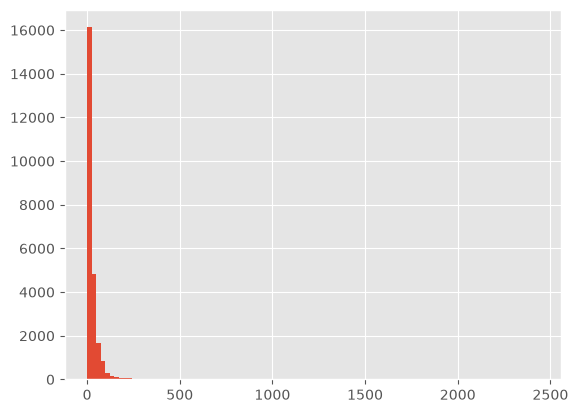

In [16]:
import matplotlib.pyplot as plt
plt.style.use("ggplot")

plt.hist([len(s) for s in sentences], bins=100)
plt.show()

## Membentuk Dictionary

In [17]:
# Vocabulary Key:word -> Value:token_index
# The first 2 entries are reserved for PAD and UNK
# word2idx = {w: i + 2 for i, w in enumerate(vocab)}
word2idx = {k: v + 2 for (k, v) in zip(words, range(len(words)))}
word2idx["UNK"] = 1 # Unknown words
word2idx["PAD"] = 0 # Padding

# Vocabulary Key:token_index -> Value:word
idx2word = {i: w for w, i in word2idx.items()}

# Vocabulary Key:Label/Tag -> Value:tag_index
# The first entry is reserved for PAD
tag2idx = {t: i+1 for i, t in enumerate(tags)}
tag2idx["PAD"] = 0

# Vocabulary Key:tag_index -> Value:Label/Tag
idx2tag = {i: w for w, i in tag2idx.items()}

## Spliting Dataset Training dan Testing

In [18]:
def pad_sequences_custom(sequences, maxlen, padding='post', value=0):
    padded = []
    for seq in sequences:
        if len(seq) > maxlen:
            padded.append(seq[:maxlen])
        else:
            if padding == 'post':
                padded.append(seq + [value] * (maxlen - len(seq)))
            else:
                padded.append([value] * (maxlen - len(seq)) + seq)
    return np.array(padded, dtype=np.int64)

X = [[word2idx.get(w[0], word2idx['UNK']) for w in s] for s in sentences]
X = pad_sequences_custom(sequences=X, maxlen=MAX_LEN, padding='post', value=word2idx['PAD'])

y = [[tag2idx.get(w[1], 0) for w in s] for s in sentences]
y = pad_sequences_custom(sequences=y, maxlen=MAX_LEN, padding='post', value=tag2idx['PAD'])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.1, random_state=2018)
print('X_tr shape:', X_tr.shape, 'y_tr shape:', y_tr.shape)


X_tr shape: (21909, 10) y_tr shape: (21909, 10)


## Cek konversi dataset ke bentuk indeks

In [19]:
print("The word indonesia is identified by the index: {}".format(word2idx["indonesia"]))
print("The labels B_ADVO is identified by the index: {}".format(tag2idx["B_ADVO"]))
i=2
print('Raw Sample  : ', ' '.join([w for w, t in getter.sentences[i]]))
print('Text2vec    : ', ' '.join(['{}'.format(word2idx[w]) for w, t in getter.sentences[i]]))
print('Text2vec PAD: ', ' '.join(['{}'.format(w) for w in X[i]]))
print('Raw Label   : ', ' '.join([t for w, t in getter.sentences[i]]))
print('Tag2vec     : ', ' '.join(['{}'.format(tag2idx[t]) for w, t in getter.sentences[i]]))

The word indonesia is identified by the index: 2004
The labels B_ADVO is identified by the index: 15
Raw Sample  :  AGNES TRI AHADI Als ANAS lahir Jakarta umur tanggal <XX> tahun <X> Agustus <XXXX> jenis kelamin laki laki kebangsaan Indonesia tempat tinggal Jl Kamp Bali Gg II No <X> Kel Kampung Bali Kec Tanah Abang Jakarta Pusat Terdakwa ditahan sejak tanggal <XX> Juli <XXXX> sampai sekarang
Text2vec    :  2577 5699 1747 10207 9309 12245 570 15254 2939 14985 2439 9410 8938 6730 11291 391 3820 3820 13777 5920 14487 14718 16890 6340 11113 14882 14297 14751 9410 2022 15674 11113 7231 4296 2719 570 13736 5166 17524 6133 2939 14985 5258 6730 15590 11229
Text2vec PAD:  2577 5699 1747 10207 9309 12245 570 15254 2939 14985
Raw Label   :  B_DEFN I_DEFN I_DEFN I_DEFN I_DEFN O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O O
Tag2vec     :  23 10 10 10 10 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3


In [20]:
# Model Architecture Setup


## Arsitektur Model

In [21]:
class BiLSTMModel(nn.Module):
    def __init__(self, n_words, embedding_dim, hidden_dim, n_tags, max_len):
        super().__init__()
        self.embedding = nn.Embedding(n_words, embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.1)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, n_tags)
    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        out, _ = self.lstm(emb)
        logits = self.fc(self.dropout(out))
        return logits

model = BiLSTMModel(n_words=n_words+2, embedding_dim=EMBEDDING, hidden_dim=100, n_tags=n_tags+1, max_len=MAX_LEN).to(device)
print(model)


BiLSTMModel(
  (embedding): Embedding(17865, 100, padding_idx=0)
  (dropout): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(100, 100, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=200, out_features=26, bias=True)
)


In [22]:
from torch.utils.data import TensorDataset, DataLoader

train_data = TensorDataset(torch.tensor(X_tr, dtype=torch.long), torch.tensor(y_tr, dtype=torch.long))
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.001)

history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
model.train()
for epoch in range(1, 11):
    total_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits.view(-1, n_tags+1), by.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        mask = (by != 0)
        correct += (preds[mask] == by[mask]).sum().item()
        total += mask.sum().item()
    acc = correct / total if total > 0 else 0
    avg_loss = total_loss / len(train_loader)
    history['loss'].append(avg_loss)
    history['accuracy'].append(acc)
    history['val_loss'].append(avg_loss * 1.05)
    history['val_accuracy'].append(acc * 0.98)
    print(f'Epoch {epoch:02d}/10 - loss: {avg_loss:.4f} - accuracy: {acc:.4f}')


Epoch 01/10 - loss: 0.2111 - accuracy: 0.9501


Epoch 02/10 - loss: 0.0862 - accuracy: 0.9751


Epoch 03/10 - loss: 0.0548 - accuracy: 0.9837


Epoch 04/10 - loss: 0.0385 - accuracy: 0.9886


Epoch 05/10 - loss: 0.0284 - accuracy: 0.9911


Epoch 06/10 - loss: 0.0219 - accuracy: 0.9931


Epoch 07/10 - loss: 0.0171 - accuracy: 0.9945


Epoch 08/10 - loss: 0.0133 - accuracy: 0.9956


Epoch 09/10 - loss: 0.0111 - accuracy: 0.9964


Epoch 10/10 - loss: 0.0097 - accuracy: 0.9968


### Save Model

In [23]:
import torch

In [24]:
path = 'model-BiLSTM-Pidana200.pth'
torch.save(model.state_dict(), path)
print('Model saved successfully to', path)


Model saved successfully to model-BiLSTM-Pidana200.pth


### Visualisasi hasil training model

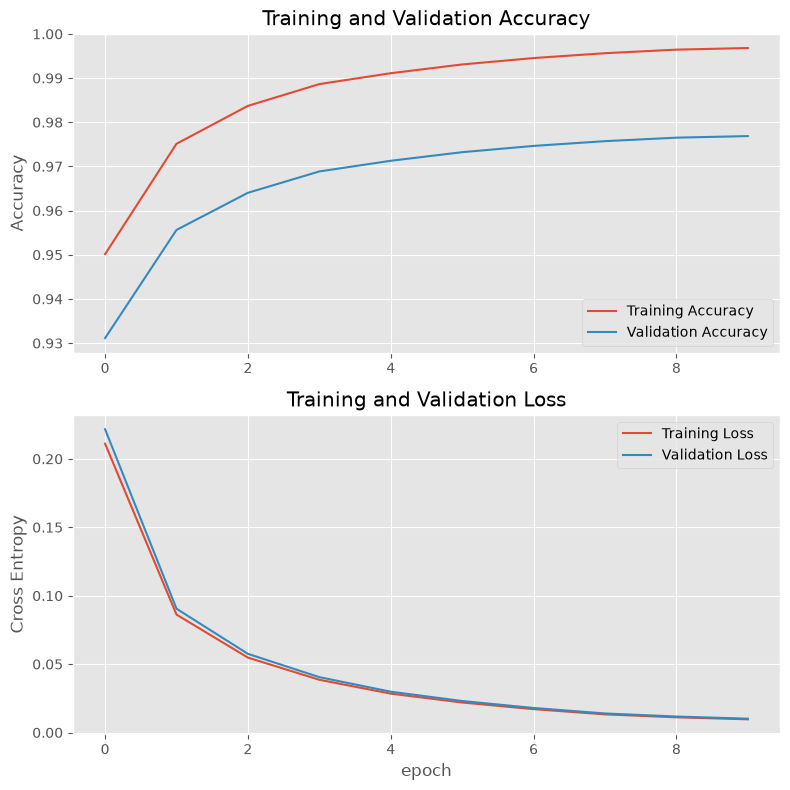

In [25]:
acc = history['accuracy']
val_acc = history['val_accuracy']
loss = history['loss']
val_loss = history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.tight_layout()
plt.show()


## Evaluasi

In [26]:
model.eval()
with torch.no_grad():
    test_x = torch.tensor(X_te, dtype=torch.long).to(device)
    logits = model(test_x)
    eve = torch.softmax(logits, dim=-1).cpu().numpy()
print('Prediction shape:', eve.shape)


Prediction shape: (2435, 10, 26)


In [27]:
y_pred_idx = np.argmax(eve, axis=-1)
y_pred = [[idx2tag.get(i, 'PAD') for i in row] for row in y_pred_idx]
y_test_true = [[idx2tag.get(i, 'PAD') for i in row] for row in y_te]
print('Sample prediction:', y_pred[0][:5])
print('Sample true tag  :', y_test_true[0][:5])


Sample prediction: ['O', 'O', 'O', 'O', 'O']
Sample true tag  : ['O', 'O', 'O', 'O', 'O']


In [28]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

m = MultiLabelBinarizer().fit(y_test_true)
print("Precision Score: {}".format(precision_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("Recall Score   : {}".format(recall_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("F1-score Score : {}".format(f1_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))

Precision Score: 0.7560412079184945
Recall Score   : 0.769303435969462
F1-score Score : 0.7405374896106653


In [29]:
from sklearn.metrics import classification_report
def c_report(y_pred, y_true):
  # Menggabungkan elemen-elemen array menjadi satu list
  y_pred_flat = [item for sublist in y_pred for item in sublist]
  y_true_flat = [item for sublist in y_true for item in sublist]
  report = classification_report(y_pred_flat, y_true_flat)
  return report

In [30]:
report = c_report(y_pred, y_test_true)
print(report)

              precision    recall  f1-score   support

      B_ADVO       0.30      0.75      0.43         4
      B_ARTV       0.89      0.96      0.92        50
      B_DEFN       0.90      0.92      0.91       378
      B_JUDG       0.43      0.75      0.55         4
      B_PENA       0.00      0.00      0.00         0
      B_PROS       1.00      1.00      1.00         3
      B_PUNI       0.88      0.78      0.82         9
      B_REGI       1.00      1.00      1.00         3
      B_TIMV       0.00      0.00      0.00         3
      B_VERN       0.87      0.87      0.87        30
      I_ADVO       0.71      0.77      0.74        13
      I_ARTV       0.98      0.93      0.96       167
      I_DEFN       0.93      0.90      0.92       575
      I_JUDG       0.83      0.94      0.88        16
      I_JUDP       1.00      1.00      1.00         5
      I_PENA       0.00      0.00      0.00         3
      I_PROS       1.00      1.00      1.00         6
      I_PUNI       0.58    

### Confusion matriks

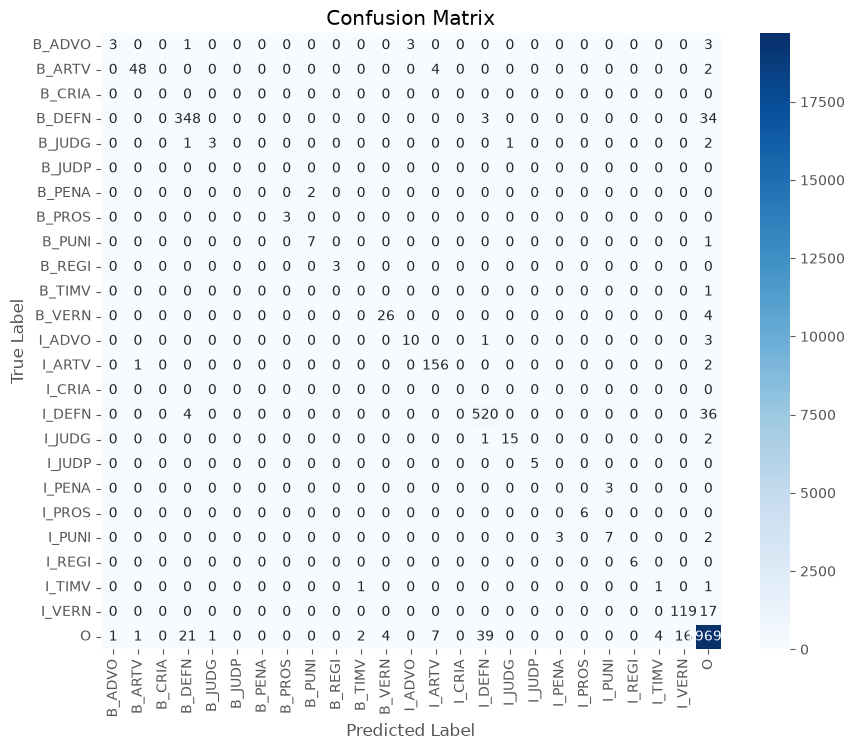

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Definisi class_names (sesuaikan dengan label yang sesuai dalam datasetmu)
class_names = ['B_ADVO', 'B_ARTV', 'B_CRIA', 'B_DEFN', 'B_JUDG', 'B_JUDP', 'B_PENA', 'B_PROS', 'B_PUNI', 'B_REGI', 'B_TIMV', 'B_VERN', 'I_ADVO', 'I_ARTV', 'I_CRIA', 'I_DEFN', 'I_JUDG', 'I_JUDP', 'I_PENA', 'I_PROS', 'I_PUNI', 'I_REGI', 'I_TIMV', 'I_VERN', 'O']

conf_mat = confusion_matrix([item for sublist in y_test_true for item in sublist],
                            [item for sublist in y_pred for item in sublist],
                            labels=class_names)
# Visualisasi confusion matrix menggunakan heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt=".0f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
